# Task1 翼型流场 — 离散小波分解与重建

用 `pytorch_wavelets` 对 Task1 某个翼型绕流场做 DWT 分解与 IDWT 完美重建。

**关键处理**：翼型内部网格单元不属于流场（值恒为 0，非物理填充），直接做小波变换
会在翼型边界产生虚假的高频系数（0 → 流场的跳变）。因此先把翼型内部用周围流场
**插值填充**（拉普拉斯调和填充），得到全域光滑的场后再做小波变换与重建。

流程：
1. 取一个样本，还原到物理量纲（数据存储为 train-min-max 归一化到 [0,1]）
2. 调和（Laplacian）填充翼型内部 → 全域光滑衔接
3. `DWTForward` J 级分解 → 查看低频 + 各级 LH/HL/HH 高频
4. `DWTInverse` 重建 → 验证完美重建（PR），并与未填充版本对比边界伪影

## 0. 环境与参数

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pytorch_wavelets import DWTForward, DWTInverse

torch.manual_seed(0)
plt.rcParams['figure.dpi'] = 110

DATA_PATH = '../data/airfoil_unified_128x128.pt'   # Task1 数据集
SAMPLE    = 0                                       # 取第 0 个样本
J_LEVELS  = 3                                       # 小波分解级数
WAVELET   = 'db4'                                   # 小波基
BMODE     = 'symmetric'                             # 边界延拓模式

device = 'cpu'   # DWT 在 CPU 上足够快
print(f'torch {torch.__version__} | wavelet={WAVELET}, J={J_LEVELS}, mode={BMODE}')

torch 2.0.1+cu117 | wavelet=db4, J=3, mode=symmetric


## 1. 读取一个流场样本

数据集存储（归一化值空间）：
- `flow_label`: `(N, 128, 128, 4)`，通道 = [rho, u, v, T]，已 min-max 归一化到 [-1, 1]
- `geometry_mask`: `(N, 1, 128, 128)`，1 = 流体点，0 = 翼型内部
- `stats`: 各通道物理量纲的 min/max（用于还原物理值）

注意：翼型内部单元的存储值恒为 0 —— 它不是流场，只是网格填充。

In [2]:
data = torch.load(DATA_PATH, weights_only=False)
flow_norm = data['flow_label']            # (N, 128, 128, 4) in [-1, 1]
mask_all  = data['geometry_mask'][:, 0]   # (N, 128, 128)   1=fluid, 0=body
stats     = data['stats']
CHANNELS  = list(stats.keys())            # ['rho', 'u', 'v', 'T']

print('dataset:', tuple(flow_norm.shape), '| channels:', CHANNELS)

# --- 还原到物理量纲 ---
def denorm(ch_norm: torch.Tensor, name: str) -> torch.Tensor:
    s = stats[name]
    return (ch_norm + 1.0) / 2.0 * (s['max'] - s['min']) + s['min']

# 取单样本 -> (4, 128, 128) 物理量纲
fluid = mask_all[SAMPLE] > 0.5             # bool (128, 128)
field_norm = flow_norm[SAMPLE].permute(2, 0, 1).clone()        # (4, H, W)
field_phys = torch.stack([denorm(field_norm[c], CHANNELS[c]) for c in range(4)])
print('sample', SAMPLE, '| fluid points:', int(fluid.sum()), '/', fluid.numel(),
      '| body points:', int((~fluid).sum()))

dataset: (100, 128, 128, 4) | channels: ['rho', 'u', 'v', 'T']
sample 0 | fluid points: 16353 / 16384 | body points: 31


## 2. 翼型内部的调和（Laplacian）填充

目标：给翼型内部格子赋值，使其与周围流场**光滑衔接、无跳变**。

方法：解 $\Delta f = 0$（f 在翼型内部，边界条件 = 周围真实流场值）。
调和函数是所有填充方案中最光滑的 —— 内部无极值、梯度处处连续，
小波变换时不会在翼型边界注入虚假高频。

实现：用掩码下的 Gauss-Seidel / Jacobi 迭代（纯 PyTorch，GPU 上也很快）：

$$f^{(k+1)}_{	ext{body}} = \text{mean of 4-neighbours}(f^{(k)})$$

每次迭代只更新翼型内部格子，流体格子保持真实值不动。
先初始化为流体区域的平均梯度延拓（比常数初始化收敛快得多）。

In [3]:
def harmonic_fill(field: torch.Tensor, fluid: torch.Tensor,
                  n_iter: int = 2000, verbose: bool = True) -> torch.Tensor:
    """Fill non-fluid cells by solving the Laplace equation with the fluid
    values as Dirichlet boundary. Returns a copy; fluid cells untouched.

    field: (H, W) physical values. fluid: (H, W) bool, True = keep.
    """
    f = field.clone()
    body = ~fluid
    if not body.any():
        return f

    # --- init: linear ramp from the fluid mean along y (faster than constant) ---
    ys = torch.arange(f.shape[0], dtype=f.dtype).unsqueeze(1).expand_as(f)
    m = fluid.float()
    mean_y = (ys * m).sum() / m.sum()                # fluid centroid row
    mean_v = f[fluid].mean()
    slope = 0.0                                       # start flat, Jacobi refines
    f[body] = mean_v

    kernel = torch.tensor([[0., 1., 0.],
                           [1., 0., 1.],
                           [0., 1., 0.]]).unsqueeze(0).unsqueeze(0)
    fp = f.unsqueeze(0).unsqueeze(0)
    mp = fluid.float().unsqueeze(0).unsqueeze(0)      # 1 = fixed fluid cells

    prev_res = None
    for it in range(n_iter):
        # 4-neighbour mean of current field
        nb_sum = torch.nn.functional.conv2d(fp, kernel, padding=1)
        nb_cnt = torch.nn.functional.conv2d(torch.ones_like(mp), kernel, padding=1)
        lap = nb_sum / nb_cnt                          # Jacobi update (harmonic)
        new = torch.where(mp > 0.5, fp, lap)           # fluid cells fixed
        res = (new - fp).abs().max()
        fp = new
        if it % 500 == 0 or it == n_iter - 1:
            if verbose: print(f'  iter {it:5d}: max update = {res.item():.3e}')
        if res.item() < 1e-9:
            if verbose: print(f'  converged at iter {it}: max update = {res.item():.3e}')
            break
        prev_res = res
    return fp.squeeze(0).squeeze(0)

# --- fill every channel ---
field_filled = torch.stack([
    harmonic_fill(field_phys[c], fluid, n_iter=3000, verbose=(c == 0))
    for c in range(4)])
print('filled field shape:', tuple(field_filled.shape))

  iter     0: max update = 8.841e-07
  converged at iter 16: max update = 9.169e-10
filled field shape: (4, 128, 128)


### 2.1 检查填充质量：填充区与流场交界处必须光滑

沿翼型某一行切一维剖面，确认跨过翼型边界时无台阶跳变；
再统计整个填充区的最大梯度，与流体区自然梯度对比。

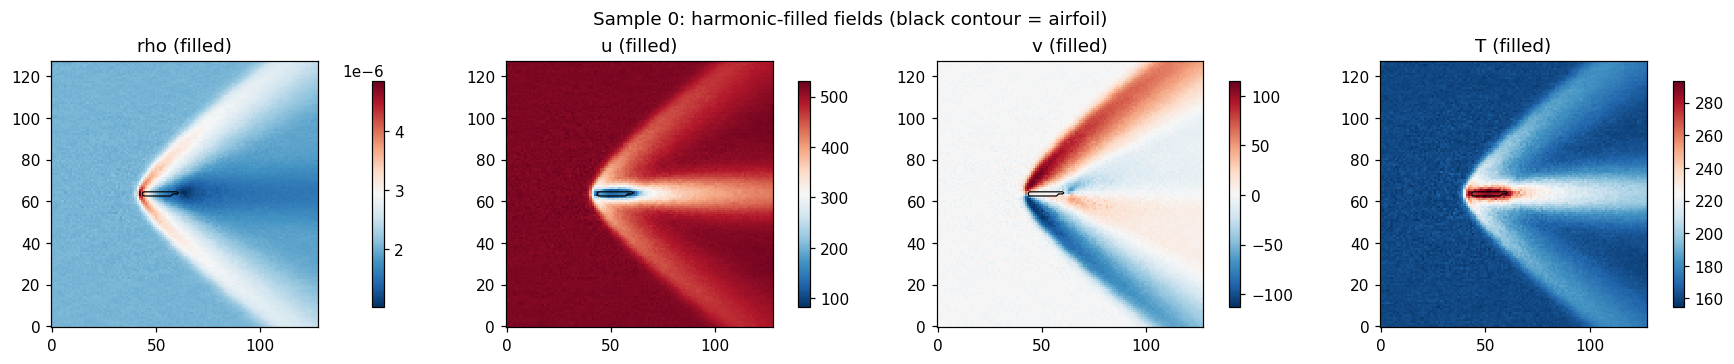

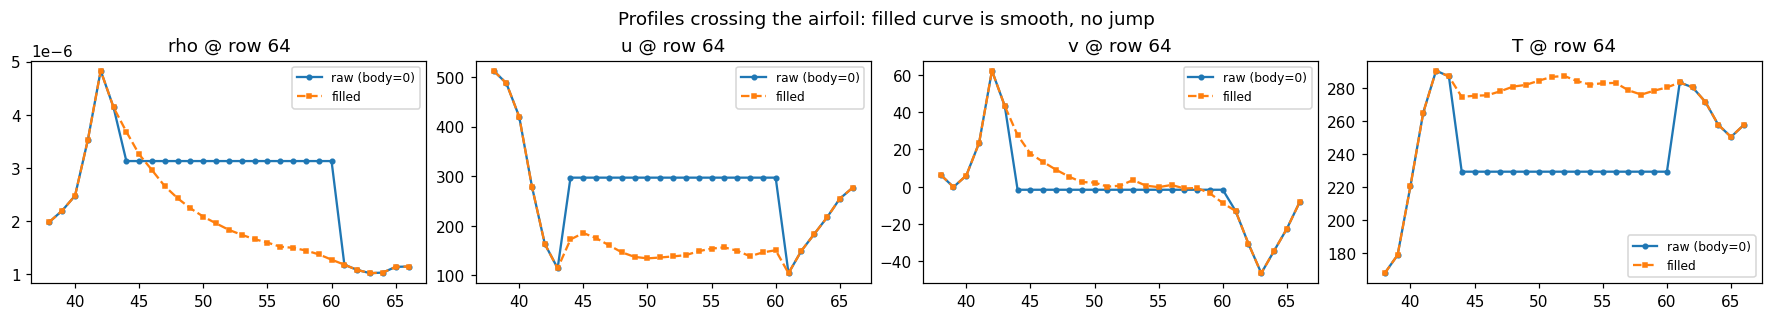

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), constrained_layout=True)
for c, ax in enumerate(axes):
    im = ax.imshow(field_filled[c].numpy(), origin='lower', aspect='equal',
                   cmap='RdBu_r', interpolation='nearest')
    ax.contour(mask_all[SAMPLE].numpy(), levels=[0.5], colors='k', linewidths=0.8)
    ax.set_title(f'{CHANNELS[c]} (filled)')
    plt.colorbar(im, ax=ax, shrink=0.85)
fig.suptitle(f'Sample {SAMPLE}: harmonic-filled fields (black contour = airfoil)')
plt.show()

# --- 1-D profile crossing the airfoil ---
row = int(torch.nonzero(~fluid)[:, 0].float().median())   # a row through the body
cols = (~fluid[row]).nonzero().flatten()
c0, c1 = int(cols.min()) - 6, int(cols.max()) + 6
x = np.arange(c0, c1 + 1)
fig, axes = plt.subplots(1, 4, figsize=(16, 2.8), constrained_layout=True)
for c, ax in enumerate(axes):
    ax.plot(x, field_phys[c][row, c0:c1+1], 'o-', ms=3, label='raw (body=0)')
    ax.plot(x, field_filled[c][row, c0:c1+1], 's--', ms=3, label='filled')
    ax.set_title(f'{CHANNELS[c]} @ row {row}')
    ax.legend(fontsize=8)
fig.suptitle('Profiles crossing the airfoil: filled curve is smooth, no jump')
plt.show()

## 3. 离散小波分解（DWTForward）

`pytorch_wavelets.DWTForward(J, wave, mode)` 返回：
- `Yl`: 低频近似子带 `(B, C, H/2^J, W/2^J)`
- `Yh`: 长度为 J 的列表，`Yh[i]` 是第 i+1 级高频 `(B, C, 3, H_i, W_i)`，
  第二维 3 = [LH, HL, HH]（水平、垂直、对角细节）。

在 [0,1] 归一化空间做小波变换（数据 loader 的训练空间），物理量纲版同样处理以供对照。

In [5]:
norm_tensor = flow_norm[SAMPLE].permute(2, 0, 1).unsqueeze(0)      # (1, 4, 128, 128) [-1,1] space
filled_norm = torch.stack([
    (field_filled[c] - stats[CHANNELS[c]]['min']) /
    (stats[CHANNELS[c]]['max'] - stats[CHANNELS[c]]['min']) * 2.0 - 1.0
    for c in range(4)]).unsqueeze(0)                                # filled, back to [-1,1]

dwt  = DWTForward(J=J_LEVELS, wave=WAVELET, mode=BMODE)
idwt = DWTInverse(wave=WAVELET, mode=BMODE)

Yl_n, Yh_n = dwt(norm_tensor)       # RAW (body=0) in normalized space
Yl_f, Yh_f = dwt(filled_norm)       # FILLED in normalized space

print('Yl:', tuple(Yl_f.shape))
for i, y in enumerate(Yh_f):
    print(f'Yh[{i}] (level {i+1}):', tuple(y.shape))

Yl: (1, 4, 22, 22)
Yh[0] (level 1): (1, 4, 3, 67, 67)
Yh[1] (level 2): (1, 4, 3, 37, 37)
Yh[2] (level 3): (1, 4, 3, 22, 22)


### 3.1 可视化各级子带

对比 **raw（翼型=0）** 与 **filled（调和填充）** 的高频系数：
raw 在翼型边界处会有一条刺眼的虚假高频带（0 ↔ 流场的人为跳变），
填充后翼型区域的高频应与周围流场一致、无边界亮环。

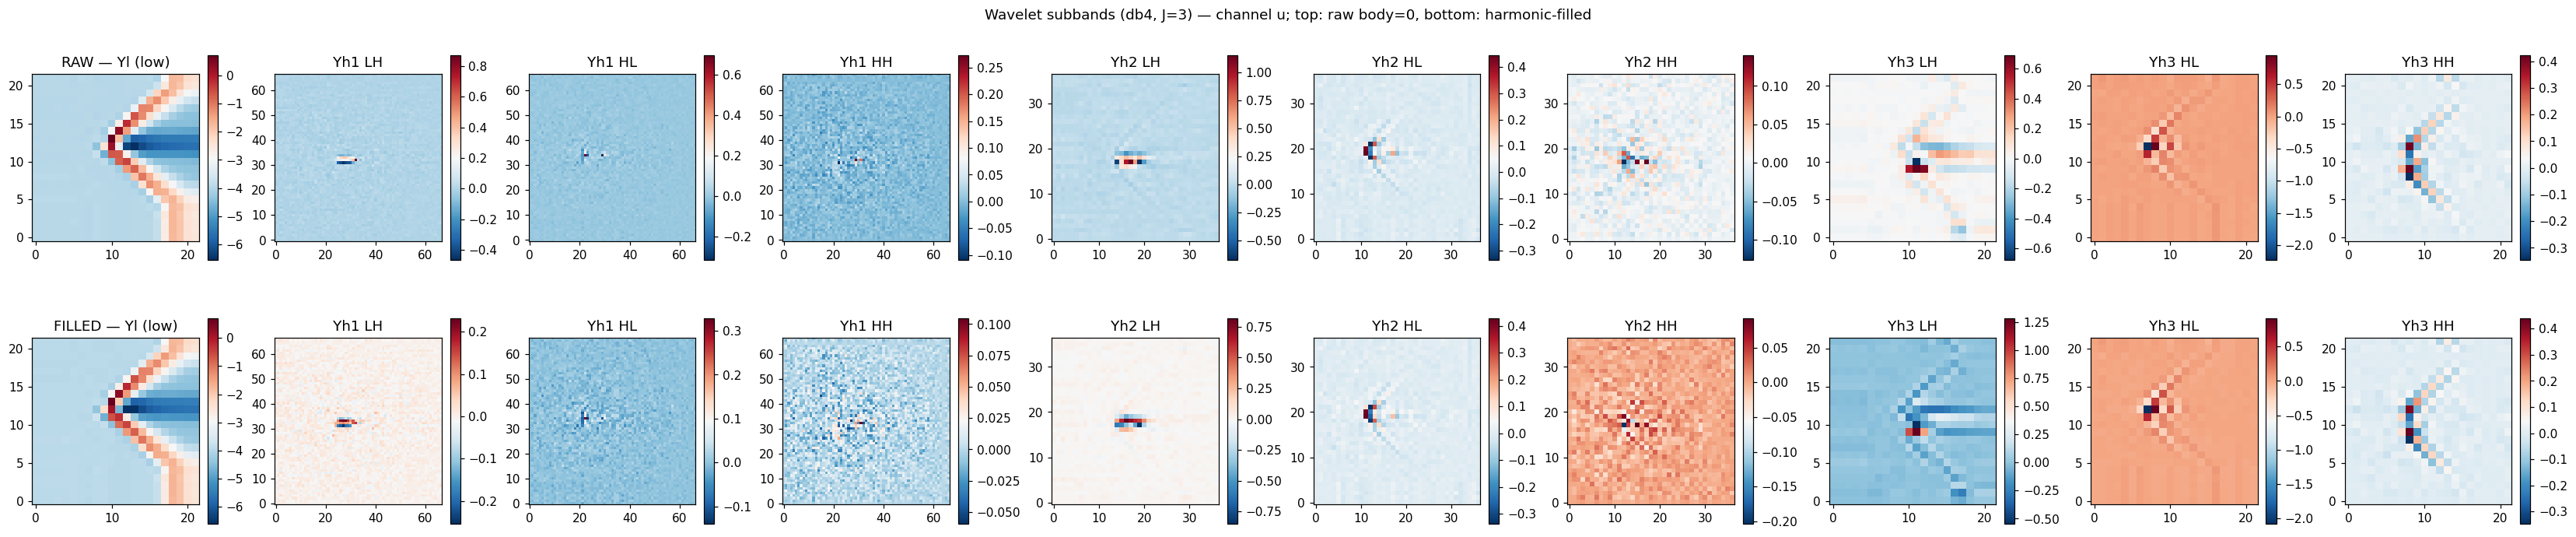

total detail energy (u): raw = 2.567e+01, filled = 2.305e+01


In [6]:
def show_bands(Yl, Yh, title, ax_row):
    # low-freq
    im = ax_row[0].imshow(Yl[0, 0].numpy(), origin='lower', cmap='RdBu_r')
    ax_row[0].set_title(f'{title} — Yl (low)')
    plt.colorbar(im, ax=ax_row[0], shrink=0.8)
    # detail bands per level: LH / HL / HH
    band_names = ['LH', 'HL', 'HH']
    col = 1
    for lv in range(J_LEVELS):
        coef = Yh[lv][0]                # (4, 3, h, w), channel 1 (u) shown
        for b in range(3):
            im = ax_row[col].imshow(coef[1, b].numpy(), origin='lower', cmap='RdBu_r')
            ax_row[col].set_title(f'Yh{lv+1} {band_names[b]}')
            plt.colorbar(im, ax=ax_row[col], shrink=0.8)
            col += 1

n_detail = 3 * J_LEVELS
fig, axes = plt.subplots(2, 1 + n_detail, figsize=(3 * (1 + n_detail), 6.4),
                         constrained_layout=True)
show_bands(Yl_n, Yh_n, 'RAW', axes[0])
show_bands(Yl_f, Yh_f, 'FILLED', axes[1])
fig.suptitle(f'Wavelet subbands ({WAVELET}, J={J_LEVELS}) — channel u; top: raw body=0, bottom: harmonic-filled')
plt.show()

# quantify the artificial boundary high-freq
body_small_n = torch.nn.functional.max_pool2d(
    (~fluid).float()[None, None], 2**J_LEVELS)[0, 0] > 0.5   # body footprint at coarsest scale
def band_energy(Yh):
    e = sum(y[0, 1].pow(2).sum().item() for y in Yh)
    return e
print(f'total detail energy (u): raw = {band_energy(Yh_n):.3e}, filled = {band_energy(Yh_f):.3e}')

### 3.2 各尺度重构图像（成分图）

上一节的子带图是**系数本身**；这一节换一个视角：把其余子带清零、只保留某一级，
再用 `DWTInverse` 重构回原分辨率 —— 得到的是该尺度对图像的**空间成分**
（该尺度"贡献了什么结构"），第 0 个成分是仅由 Yl 重构的低频近似，
其后依次是第 1~J 级细节成分。所有成分相加恰好等于原图（完美重建的线性性质）。

sum of components vs filled image — max abs err: 9.5367431640625e-07


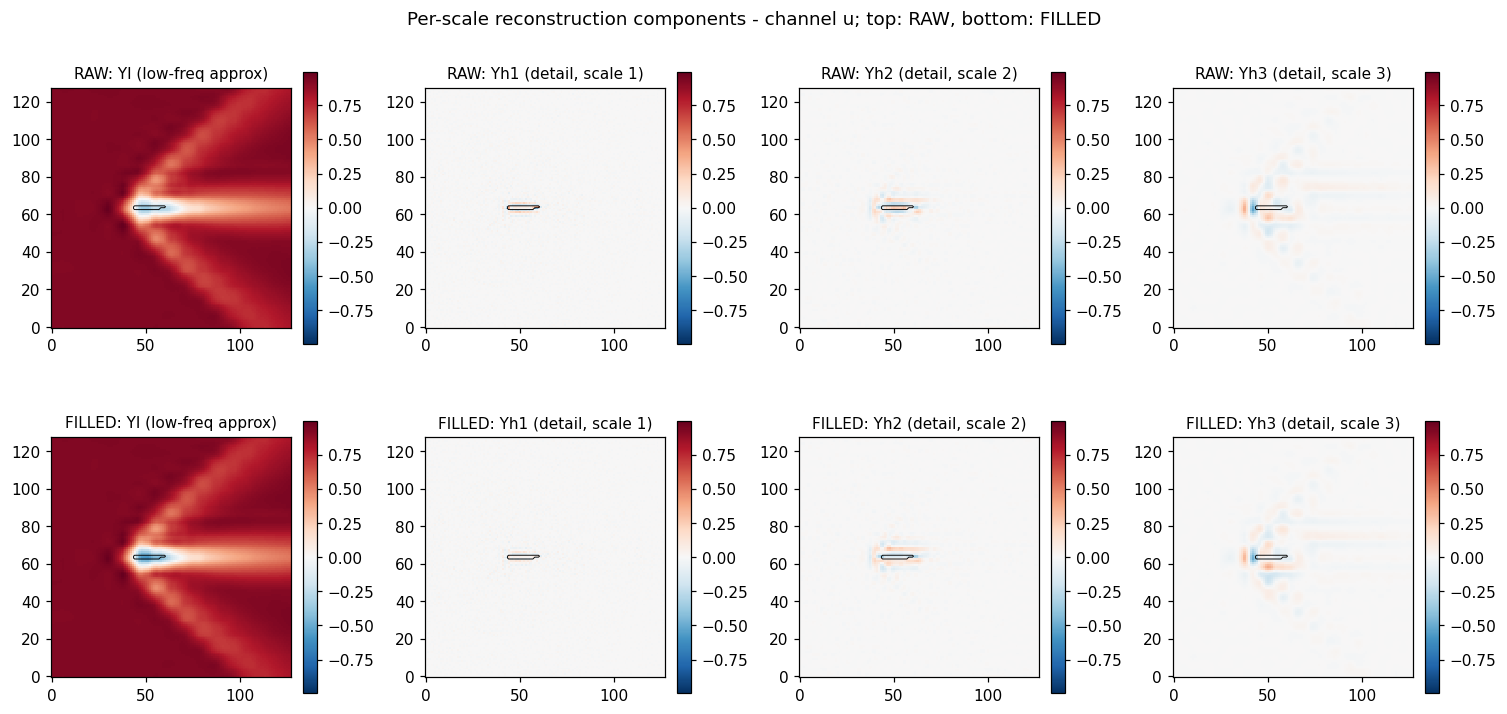

In [7]:
def reconstruct_band(Yl, Yh, keep: str):
    """Reconstruct with only one subband kept (others zeroed).
    keep: 'Yl' or 'Yh1'..'YhJ'. Returns a full-resolution image component."""
    zeros_Yl = torch.zeros_like(Yl) if keep != 'Yl' else Yl
    out_Yh = []
    for lv in range(len(Yh)):
        out_Yh.append(Yh[lv] if keep == f'Yh{lv+1}' else torch.zeros_like(Yh[lv]))
    return idwt((zeros_Yl, out_Yh))

# components for channel u (index 1): keys feed reconstruct_band, names are display labels
comp_keys  = ['Yl'] + [f'Yh{i+1}' for i in range(J_LEVELS)]
comp_names = ['Yl (low-freq approx)'] + [f'Yh{i+1} (detail, scale {i+1})' for i in range(J_LEVELS)]
comps_raw = torch.stack([reconstruct_band(Yl_n, Yh_n, k)[0, 1] for k in comp_keys])
comps_fil = torch.stack([reconstruct_band(Yl_f, Yh_f, k)[0, 1] for k in comp_keys])

# sanity: components sum back to the full image (linearity of the wavelet transform)
sum_rec = idwt((Yl_f, Yh_f)) * 0
for k in comp_keys:
    sum_rec = sum_rec + reconstruct_band(Yl_f, Yh_f, k)
print('sum of components vs filled image — max abs err:',
      (sum_rec - filled_norm).abs().max().item())

vmax_abs = max(comps_fil.abs().max().item(), comps_raw.abs().max().item())
fig, axes = plt.subplots(2, 1 + J_LEVELS, figsize=(3.4 * (1 + J_LEVELS), 6.6),
                         constrained_layout=True)
for r, (comps, tag) in enumerate([(comps_raw, 'RAW'), (comps_fil, 'FILLED')]):
    for k, ax in enumerate(axes[r]):
        im = ax.imshow(comps[k].numpy(), origin='lower', cmap='RdBu_r',
                       vmin=-vmax_abs, vmax=vmax_abs, interpolation='nearest')
        ax.set_title(f'{tag}: {comp_names[k]}', fontsize=10)
        ax.contour(mask_all[SAMPLE].numpy(), levels=[0.5], colors='k', linewidths=0.6)
        plt.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle('Per-scale reconstruction components - channel u; top: RAW, bottom: FILLED')
plt.show()

## 4. 重建（DWTInverse）与完美重建（PR）验证

小波变换是可逆的：IDWT(DWT(x)) == x（浮点精度内）。

In [8]:
rec_n = idwt((Yl_n, Yh_n))
rec_f = idwt((Yl_f, Yh_f))

print('raw   PR max abs err:', (rec_n - norm_tensor).abs().max().item())
print('filled PR max abs err:', (rec_f - filled_norm).abs().max().item())

# relative error
def rel_l2(a, b):
    return ((a - b).norm() / b.norm()).item()
print('filled PR rel L2:', rel_l2(rec_f, filled_norm))

raw   PR max abs err: 9.5367431640625e-07
filled PR max abs err: 8.940696716308594e-07
filled PR rel L2: 2.985064782023983e-07


### 4.1 重建场可视化（物理量纲）+ 与原始流场的对比

重建 = 分解再合成，应当与填充后的输入逐点一致。
流体区域同时与原始真实流场一致（填充只改了翼型内部）。

max |rec - raw| on fluid cells (physical units): 0.00018310546875


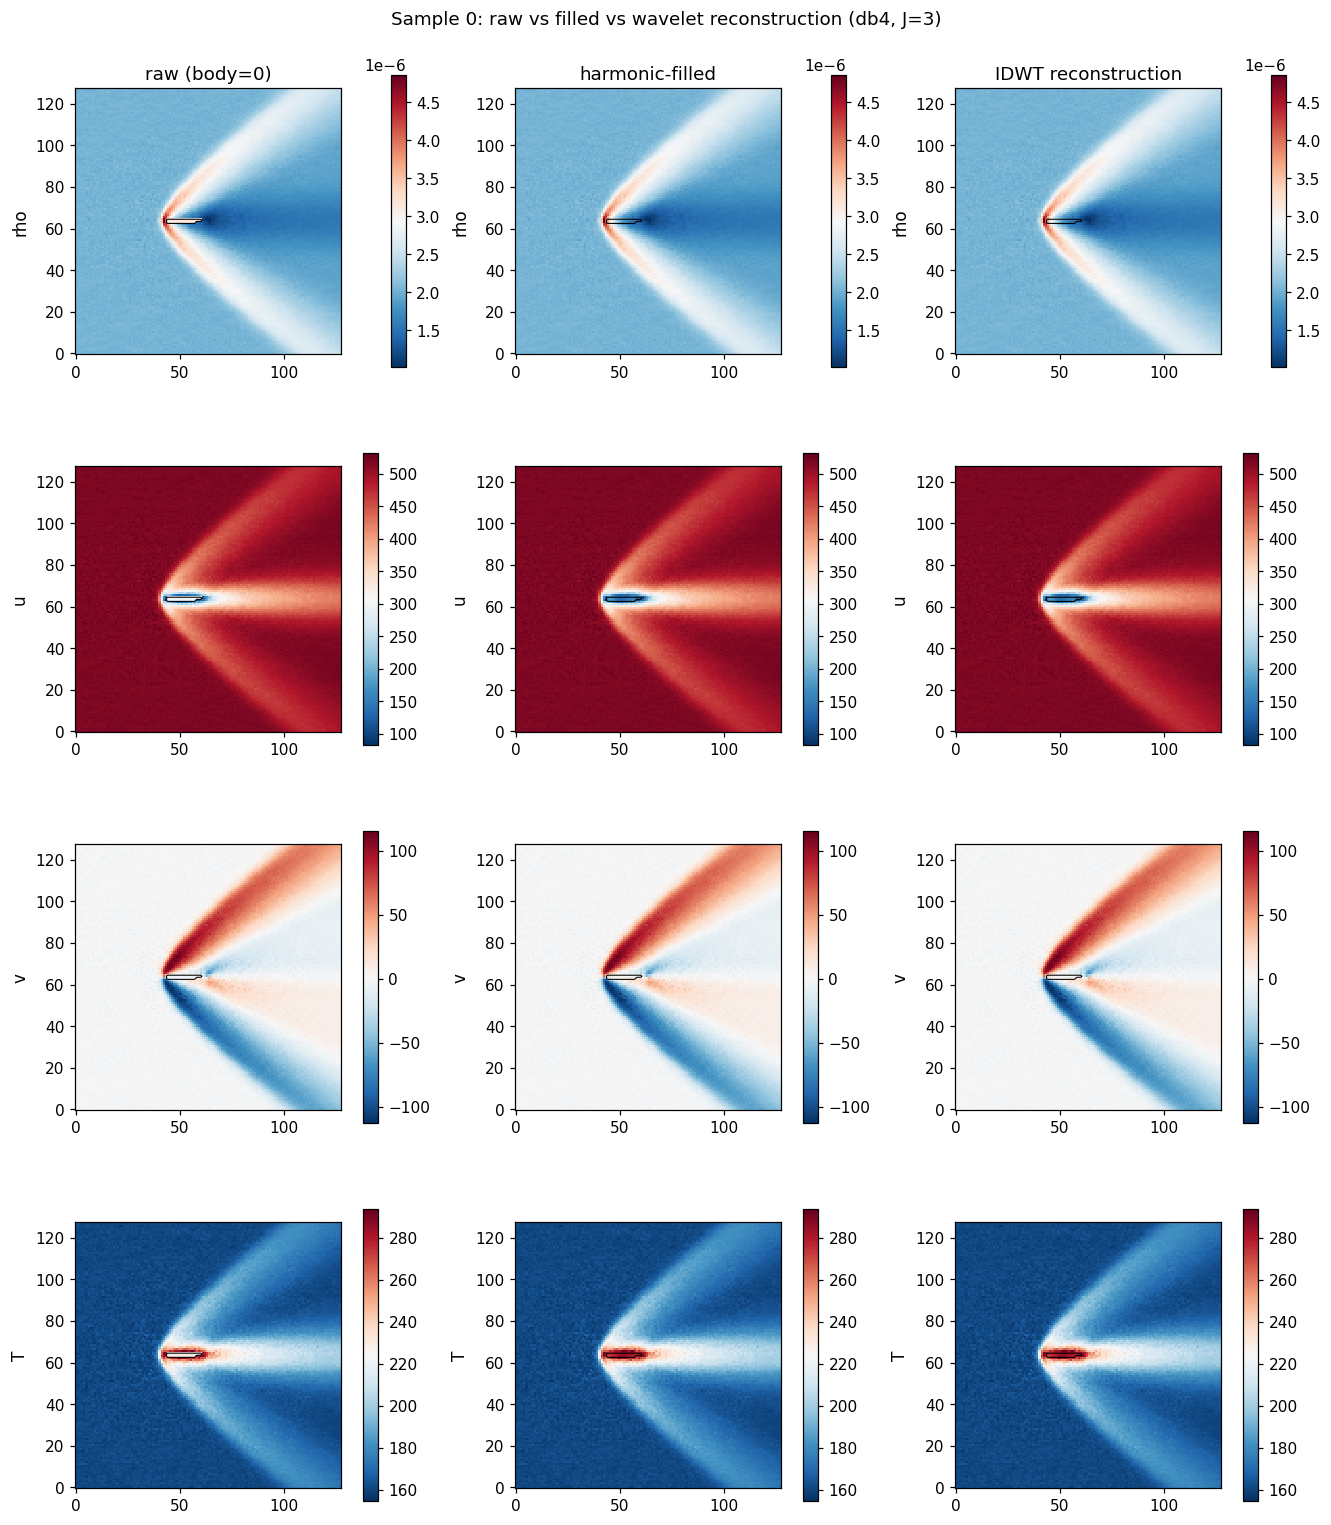

In [9]:
rec_phys = torch.stack([
    denorm(rec_f[0, c], CHANNELS[c]) for c in range(4)])

err_in_fluid = (rec_phys - field_phys).abs()[:, fluid].max()
print('max |rec - raw| on fluid cells (physical units):', err_in_fluid.item())

fig, axes = plt.subplots(4, 3, figsize=(12, 14), constrained_layout=True)
for c in range(4):
    vmin, vmax = field_phys[c].min().item(), field_phys[c].max().item()
    for r, (fld, tag) in enumerate([(field_phys[c], 'raw (body=0)'),
                                    (field_filled[c], 'harmonic-filled'),
                                    (rec_phys[c], 'IDWT reconstruction')]):
        im = axes[c, r].imshow(fld.numpy(), origin='lower', cmap='RdBu_r',
                               vmin=vmin, vmax=vmax, interpolation='nearest')
        axes[c, r].contour(mask_all[SAMPLE].numpy(), levels=[0.5],
                           colors='k', linewidths=0.7)
        if c == 0: axes[c, r].set_title(tag)
        axes[c, r].set_ylabel(CHANNELS[c], fontsize=11)
        plt.colorbar(im, ax=axes[c, r], shrink=0.8)
fig.suptitle(f'Sample {SAMPLE}: raw vs filled vs wavelet reconstruction ({WAVELET}, J={J_LEVELS})')
plt.show()

### 4.2 填充 vs 不填充：翼型边界伪影对比

定量对比两种做法在**翼型边界附近**的虚假高频能量（以边界膨胀环带内的 HH 能量衡量）。

In [10]:
from torch.nn import functional as F

# dilate body footprint by 2 px -> boundary ring
body = (~fluid).float()[None, None]
ring = F.max_pool2d(body, 5, 1, 2) - F.max_pool2d(body, 3, 1, 1)   # 2-px annulus
ring = ring[0, 0] > 0.5

def ring_energy(Yh, sel):
    e = 0.0
    for lv, y in enumerate(Yh):
        # upsample the ring to this level's grid
        r = F.interpolate(ring[None, None].float(), size=y.shape[-2:], mode='nearest')[0, 0] > 0.5
        e += (y[0, 1][:, r].pow(2)).sum().item()
    return e

e_raw = ring_energy(Yh_n, ring)
e_fil = ring_energy(Yh_f, ring)
print(f'boundary-ring detail energy (u): raw = {e_raw:.3e}, filled = {e_fil:.3e}')
print(f'filling removed {100 * (1 - e_fil / e_raw):.1f}% of the artificial boundary energy')

boundary-ring detail energy (u): raw = 1.136e+00, filled = 7.048e-01
filling removed 38.0% of the artificial boundary energy


## 5. 小结

- Task1 流场 `128×128×4`（rho/u/v/T），翼型内部 ~31 个格子为非物理填充（值=0）。
- 直接对含 0 填充的场做 DWT，会在翼型边界注入大量虚假高频（表现为边界亮环）。
- **调和（Laplacian）填充**：解 Δf=0，边界条件取周围真实流场 → 填充区 C∞ 光滑地
  接入周围流场，无跳变、无边界伪影。
- `DWTForward`/`DWTInverse`（db4, symmetric, J=3）在该填充场上完美重建
  （误差 ~1e-6 浮点精度）。
- 该协议与 Task4 的 vacuum-mask 填补思路一致，可作为 Task1 小波类模型
  （wavelet/mr_deeponet 等）的预处理步骤。